In [ ]:
# Resolve defaults from this project's root, independently of the working directory.
from pathlib import Path as _KSPath
import sys as _ks_sys
from functools import partial as _ks_partial
_ks_start = _KSPath.cwd()
_ks_root = next((p for p in (_ks_start, *_ks_start.parents) if (p / 'kinspec_paths.py').is_file()), None)
if _ks_root is None:
    raise RuntimeError('Cannot locate the KinSPEC project root containing kinspec_paths.py. Start the notebook kernel from the project directory or a subdirectory.')
_ks_sys.path.insert(0, str(_ks_root))
from kinspec_paths import ROOT as KINSPEC_ROOT, project_path as _ks_project_path
_kp = _ks_partial(_ks_project_path, script_dir='others/draw_figures/vsds')
import os as _ks_os
_ks_os.chdir(KINSPEC_ROOT / 'others/draw_figures/vsds')



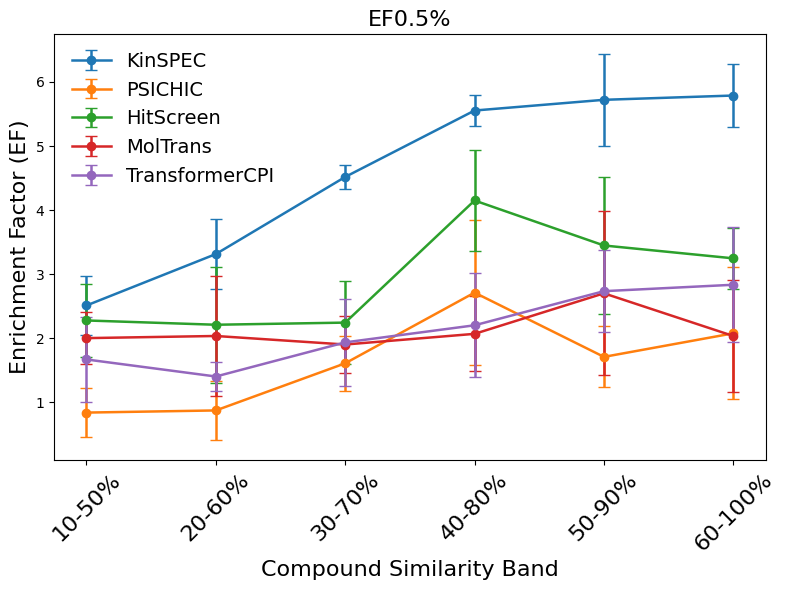

<Figure size 640x480 with 0 Axes>

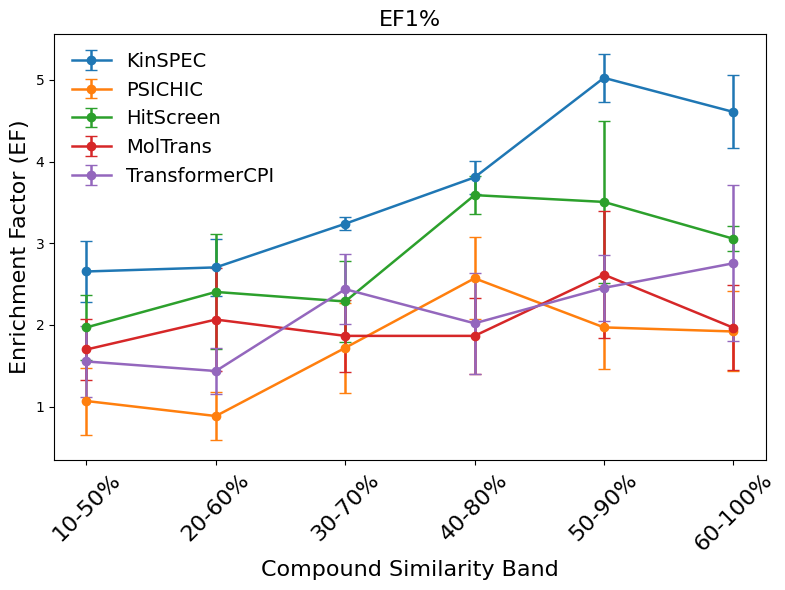

<Figure size 640x480 with 0 Axes>

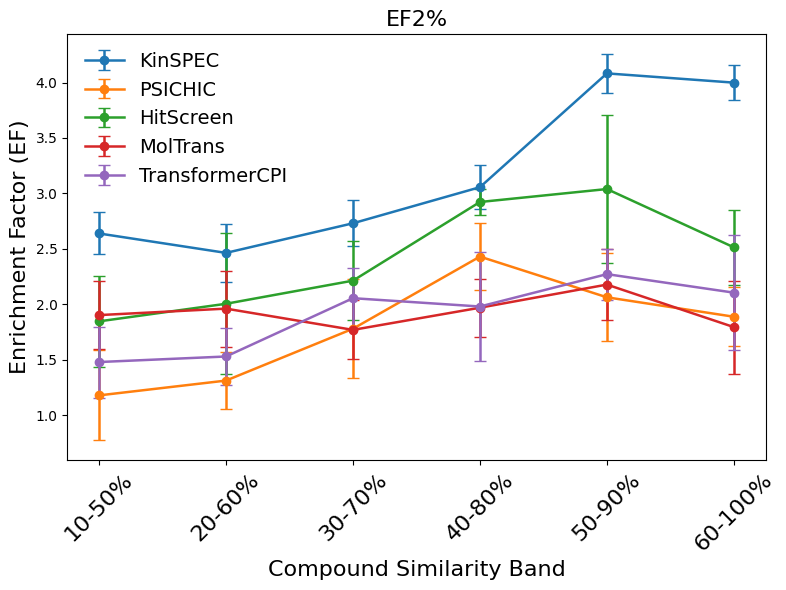

<Figure size 640x480 with 0 Axes>

In [6]:
import matplotlib.pyplot as plt

# =========================
# 1. Data
# =========================
bands = ['10-50%', '20-60%', '30-70%', '40-80%', '50-90%', '60-100%']

mean_data = {
    'EF0.5%': {
        'KinSPEC':      [2.5095, 3.3126, 4.5171, 5.5544, 5.7217, 5.7886],
        'PSICHIC':        [0.8365, 0.87, 1.6061, 2.7103, 1.7065, 2.0745],
        'HitScreen':      [2.2753, 2.2084, 2.2418, 4.1491, 3.4464, 3.2457],
        'MolTrans':       [1.9996, 2.0329, 1.8996, 2.0662, 2.6994, 2.0329],
        'TransformerCPI': [1.666, 1.4, 1.933, 2.2, 2.733, 2.833],
    },
    'EF1%': {
        'KinSPEC':      [2.6547, 2.7048, 3.2391, 3.8068, 5.0256, 4.6082],
        'PSICHIC':        [1.0686, 0.8849, 1.7197, 2.5713, 1.9702, 1.9201],
        'HitScreen':      [1.9702, 2.4043, 2.2874, 3.5897, 3.5063, 3.0555],
        'MolTrans':       [1.6996, 2.0662, 1.8663, 1.8663, 2.6161, 1.9662],
        'TransformerCPI': [1.553, 1.436, 2.438, 2.02, 2.454, 2.755],
    },
    'EF2%': {
        'KinSPEC':      [2.638, 2.4627, 2.7299, 3.0555, 4.0823, 3.9988],
        'PSICHIC':        [1.1771, 1.3107, 1.7782, 2.4293, 2.062, 1.8867],
        'HitScreen':      [1.845, 2.0036, 2.2123, 2.9219, 3.0388, 2.5128],
        'MolTrans':       [1.9015, 1.9599, 1.7681, 1.9682, 2.1767, 1.7931],
        'TransformerCPI': [1.478, 1.528, 2.054, 1.979, 2.271, 2.104],
    }
}

std_data = {
    'KinSPEC': {
        'EF0.5%': [0.4612, 0.5437, 0.1833, 0.2459, 0.7208, 0.4918],
        'EF1%':   [0.3785, 0.3526, 0.0818, 0.2017, 0.2959, 0.4461],
        'EF2%':   [0.1893, 0.2613, 0.2089, 0.1965, 0.1779, 0.1548],
    },
    'PSICHIC': {
        'EF0.5%': [0.3815, 0.466, 0.4311, 1.1367, 0.4779, 1.0291],
        'EF1%':   [0.4103, 0.2968, 0.5477, 0.502, 0.5053, 0.4896],
        'EF2%':   [0.405, 0.254, 0.4446, 0.3038, 0.3956, 0.2671],
    },
    'HitScreen': {
        'EF0.5%': [0.5757, 0.9065, 0.6479, 0.7946, 1.0718, 0.4802],
        'EF1%':   [0.3972, 0.7032, 0.4918, 0.2301, 0.9948, 0.1548],
        'EF2%':   [0.4085, 0.6347, 0.3564, 0.1151, 0.6717, 0.3354],
    },
    'MolTrans': {
        'EF0.5%': [0.4082, 0.9382, 0.4502, 0.5844, 1.2821, 0.877],
        'EF1%':   [0.3754, 0.6356, 0.4432, 0.4661, 0.774, 0.5223],
        'EF2%':   [0.3073, 0.3426, 0.2664, 0.2627, 0.3222, 0.4201],
    },
    'TransformerCPI': {
        'EF0.5%': [0.658, 0.226, 0.68, 0.812, 0.638, 0.9],
        'EF1%':   [0.44, 0.286, 0.43, 0.617, 0.401, 0.956],
        'EF2%':   [0.32, 0.257, 0.274, 0.489, 0.231, 0.521],
    }
}

# =========================
# 2. Plotting
# =========================
metrics = ['EF0.5%', 'EF1%', 'EF2%']
models = ['KinSPEC', 'PSICHIC', 'HitScreen', 'MolTrans', 'TransformerCPI']

for metric in metrics:
    plt.figure(figsize=(8, 6))
    
    for model in models:
        y = mean_data[metric][model]
        yerr = std_data[model][metric]
        
        plt.errorbar(
            bands, y, yerr=yerr,
            marker='o',
            linestyle='-',
            capsize=4,
            linewidth=1.8,
            markersize=6,
            label=model
        )
    
    plt.xlabel('Compound Similarity Band', fontsize=16)
    plt.ylabel('Enrichment Factor (EF)', fontsize=16)
    plt.title(metric, fontsize=16)
    plt.xticks(rotation=45,fontsize=16)
    plt.legend(frameon=False,fontsize=14)
    plt.tight_layout()
    plt.show()

    # Uncomment the following line to save the figure
    plt.savefig(f'{metric}_lineplot_with_errorbar.png', dpi=300, bbox_inches='tight')

In [2]:
import matplotlib; print(matplotlib.get_backend())

module://matplotlib_inline.backend_inline
